# 07 · Defensive contributions, saves, cards & bonus

The remaining scoring components. Each is again evaluated **given the minutes actually played** (rolling backtest,
2024-25 onwards, retrained every 5 gameweeks); minutes uncertainty is combined in notebook 08.

| Component | Points | Approach |
|---|---|---|
| Defensive contribution | +2 if CBIT ≥ 10 (DEF) / CBIRT ≥ 12 (MID, FWD) | expected **count**, then P(count ≥ threshold) |
| Goalkeeper saves | +1 per 3 saves | expected saves, then expected save points |
| Yellow / red cards | −1 / −3 | personal card rate, shrunk to the position average |
| Bonus | +1 to +3 | learned from what happens **in the match** (goals, assists, clean sheet, …) |

Code: [`fpl_engine/models/defensive.py`](../fpl_engine/models/defensive.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db, backtest
from fpl_engine.models import defensive as dm
from fpl_engine.models.dataset import load_model_frame
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
with db.connect() as conn:
    f, matches = load_model_frame(conn)
f = dm.add_match_scores(f, matches)
f['y_saves'] = f.y_saves.astype(float)
print(f'{len(f):,} player-fixture rows')

145,943 player-fixture rows


## 1 · Defensive contributions

**Why a count model?** The 2 points depend on crossing a line, and how *likely* that is depends on both a player's
typical number and how much it varies. A defender who averages 9 actions crosses 10 often; one who averages 6 rarely.

`expected count = his recent rate per 90 (definition-adjusted, notebook 01b) × minutes/90 × home/away effect × pressure effect`

- **pressure** = how many goals his team is expected to concede (notebook 05). Teams under the cosh defend more.
- **negative binomial** = a Poisson that allows some matches to be much busier than others (a backs-to-the-wall away
  game). It makes the "≥ 10" probability realistic.

In [2]:
dc_rows = lambda d: (d.y_minutes > 0) & d.position.isin(['DEF', 'MID', 'FWD']) & d.team_lam_against.notna() & d.y_dc.notna()
variants = {'negative binomial + home & pressure + recalibration': lambda: dm.DefensiveContributionModel(),
            'negative binomial + home & pressure (no recalibration)': lambda: dm.DefensiveContributionModel(recalibrate=False),
            'Poisson + home & pressure': lambda: dm.DefensiveContributionModel(dispersion=False, recalibrate=False),
            'negative binomial, no context': lambda: dm.DefensiveContributionModel(context=False, recalibrate=False),
            'baseline: Poisson on last-10 rate': lambda: dm.HitRateBaseline()}
res, dc_out = {}, None
for name, fac in variants.items():
    o = backtest.rolling_component(f, fac, dc_rows)
    y = (o.y_dc >= o.position.map(dm.DC_THRESHOLD)).astype(float); p = o.p_dc.clip(1e-6, 1 - 1e-6)
    res[name] = {'Brier': ((p - y) ** 2).mean(), 'log loss': -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean(),
                 'predicted hit rate': p.mean(), 'actual hit rate': y.mean()}
    if dc_out is None: dc_out = o
pd.DataFrame(res).T.round(4)

,Brier,log loss,predicted hit rate,actual hit rate
negative binomial + home & pressure + recalibration,0.0819,0.2609,0.1199,0.1236
negative binomial + home & pressure (no recalibration),0.0821,0.2621,0.1363,0.1236
Poisson + home & pressure,0.0825,0.2636,0.1256,0.1236
"negative binomial, no context",0.0824,0.2629,0.1367,0.1236
baseline: Poisson on last-10 rate,0.0847,0.2703,0.1277,0.1236


At home: ×0.962 defensive actions · per doubling of expected goals against: ×1.042
negative-binomial size by position (lower = more match-to-match variation): {'DEF': 15.7, 'MID': 16.8, 'FWD': 12.1}


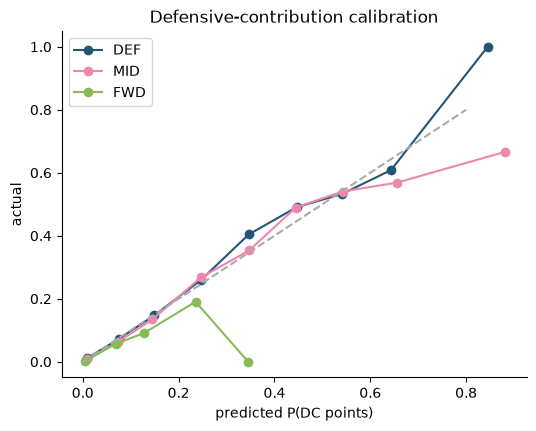

In [3]:
latest = dm.DefensiveContributionModel().fit(f[f.season >= '2022-23'])
coef = dict(zip(['home', 'pressure'], latest.glm.coef_))
print(f"At home: ×{np.exp(coef['home']):.3f} defensive actions · per doubling of expected goals against: ×{2 ** coef['pressure']:.3f}")
print('negative-binomial size by position (lower = more match-to-match variation):', {k: round(v, 1) for k, v in latest.size.items()})
y = (dc_out.y_dc >= dc_out.position.map(dm.DC_THRESHOLD)).astype(float)
cal = pd.DataFrame({'p': dc_out.p_dc, 'y': y, 'pos': dc_out.position})
fig, ax = plt.subplots(figsize=(6, 4.5))
for pos, c in [('DEF', '#257'), ('MID', '#e8a'), ('FWD', '#8b5')]:
    d = cal[cal.pos == pos]
    b = d.groupby(pd.cut(d.p, [0, .05, .1, .2, .3, .4, .5, .6, .8, 1]), observed=True).agg(pred=('p', 'mean'), act=('y', 'mean'))
    ax.plot(b.pred, b.act, marker='o', label=pos, color=c)
ax.plot([0, .8], [0, .8], '--', color='#aaa'); ax.set_xlabel('predicted P(DC points)'); ax.set_ylabel('actual'); ax.legend()
ax.set_title('Defensive-contribution calibration'); plt.show()

The home/away input you asked for in notebook 05 shows up here: players make slightly **fewer** defensive actions at
home and **more** against stronger attacks. The negative binomial beats a plain Poisson, and the full model beats the
simple baseline.

**Recalibration (your decision):** the raw model was over-confident at the high end (saying 70–80% when ~58% happened).
To fix it *without overfitting* we use **Platt scaling**: `logit(p_final) = a + b·logit(p_raw)`, just **two numbers**,
shared by all positions, fitted on the latest 365 days (~20,000 appearances) and re-fitted at every retrain. It improves
Brier and log loss slightly and pulls the top end in. Fitted on the latest year it's almost the identity
(a ≈ −0.03, b ≈ 1.01): its job is to absorb season-to-season drift, not to reshape the model. (The attacking model's
calibration is similarly minimal: one multiplier per position.) Forwards rarely reach 12, so their curve is noisy.

## 2 · Goalkeeper saves

In [4]:
gk_rows = lambda d: (d.y_minutes > 0) & (d.position == 'GKP') & d.team_lam_against.notna()
res = {}
for name, fac in {'negative binomial + home & pressure': lambda: dm.SavesModel(),
                  'baseline: Poisson, no context': lambda: dm.SavesModel(dispersion=False, context=False)}.items():
    o = backtest.rolling_component(f, fac, gk_rows); actual = np.floor(o.y_saves / 3)
    res[name] = {'save-points MAE': (o.x_save_pts - actual).abs().mean(), 'predicted save pts': o.x_save_pts.mean(),
                 'actual save pts': actual.mean()}
pd.DataFrame(res).T.round(4)

,save-points MAE,predicted save pts,actual save pts
negative binomial + home & pressure,0.5601,0.6428,0.6272
"baseline: Poisson, no context",0.5666,0.6385,0.6272


Keepers facing stronger attacks make more saves (and concede more: that's the clean-sheet side from notebook 05,
so the model naturally captures the "busy keeper" trade-off).

## 3 · Cards

In [5]:
o = backtest.rolling_component(f, lambda: dm.CardsModel(), lambda d: d.y_minutes > 0)
y = (o.y_yellow > 0).astype(float)
pos_avg = o.groupby('position').y_yellow.transform(lambda s: (s > 0).mean())
pd.DataFrame({'Brier': [((o.p_yellow - y) ** 2).mean(), ((pos_avg - y) ** 2).mean()],
              'predicted rate': [o.p_yellow.mean(), pos_avg.mean()], 'actual rate': [y.mean(), y.mean()]},
             index=['personal rate (shrunk)', 'baseline: position average']).round(4)

,Brier,predicted rate,actual rate
personal rate (shrunk),0.1108,0.1174,0.1287
baseline: position average,0.1116,0.1287,0.1287


Personal card rates help only a little: bookings are mostly random. It's a small term (−1 point × ~12%), so this is fine.

## 4 · Bonus

Bonus goes to the top 3 **BPS** scorers in each match, and BPS is driven by what happens: goals, assists, clean sheets,
saves, defensive work. So instead of predicting bonus directly, the model learns **E[bonus | the match's events]**. In
notebook 08's simulation, each simulated match produces events, then bonus consistent with them (a simulated brace
earns bonus; a quiet game doesn't).

Here it's evaluated given the **actual** events, to check it has learned the relationship:

In [6]:
bo = backtest.rolling_component(f, lambda: dm.BonusModel(), lambda d: d.y_minutes > 0)
base = bo.bonus90_ewm5.fillna(0) * bo.y_minutes.clip(upper=90) / 90
pd.DataFrame({'MAE': [(bo.pred - bo.y_bonus).abs().mean(), (base - bo.y_bonus).abs().mean()],
              'correlation with actual bonus': [bo.pred.corr(bo.y_bonus), base.corr(bo.y_bonus)]},
             index=['bonus model (given match events)', 'baseline: bonus/90 × minutes']).round(3)

,MAE,correlation with actual bonus
bonus model (given match events),0.149,0.800
baseline: bonus/90 × minutes,0.354,0.229


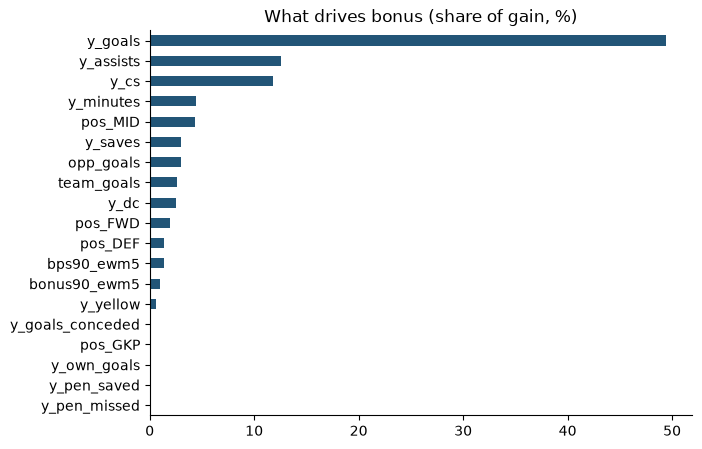

In [7]:
bm = dm.BonusModel().fit(f[(f.season >= '2022-23')])
imp = pd.Series(bm.reg.booster_.feature_importance('gain'), index=bm.features)
(imp / imp.sum() * 100).sort_values().plot.barh(color='#257', figsize=(7, 5)); plt.title('What drives bonus (share of gain, %)'); plt.show()

Goals and clean sheets dominate, then the team's goals, defensive actions and saves, plus a player's own BPS habits
(some players rack up BPS through passing and recoveries).

---
## ✅ Decisions (made with you, 2026-11-23)
1. **All four components adopted:** negative-binomial defensive contributions (home & pressure), negative-binomial
   saves, shrunk card rates, event-based bonus.
2. **Recalibration from the last 365 days**, kept deliberately small to avoid overfitting: 2-parameter Platt scaling
   for defensive contributions; one multiplier per position for goals/assists (notebook 06).
3. **Notebook 08:** simulate each player-fixture 10,000 times (minutes → team goals → goals/assists → clean sheet /
   goals conceded → defensive actions → saves → cards → bonus), score with 2026-27 rules, sum double gameweeks; full
   backtest vs the baselines and the direct LightGBM benchmark on the top-20 picks metric; live predictions with the
   availability overlay and penalty takers.